# PCA der Primärtumoren: Bilden die Tumortypen eigene Gruppen?

**Forschungsfrage:** Bilden die Tumortypen in der Genexpression eigene Gruppen, und wo weichen die Gruppen von den Tumortypen ab?

Abweichungen gibt es in zwei Richtungen: **Zusammenlegungen** (mehrere Tumortypen liegen gemeinsam) und **Aufspaltungen**
(ein Tumortyp verteilt sich auf mehrere Gruppen). Der Tumortyp ist die Referenz; Organ und Gewebetyp dienen nur zur Erklärung der Ergebnisse.

Dieses Notebook ist ein **erster, bewusst einfacher Durchlauf** mit PCA (*Principal Component Analysis*, Hauptkomponentenanalyse).
Viele Details (Batch-Effekte, Geschlecht, Qualitätsfilter, Genauswahl …) lassen wir absichtlich weg; sie stehen am Ende als offene Fragen.

**Voraussetzung:** `notebook_tcga_daten.ipynb` wurde einmal ausgeführt. Es erzeugt die hier verwendeten Dateien in `data/pancanatlas/`.

## Aufbau

1. Daten laden und Primärtumoren auswählen
2. Vorbereitung: fehlende Werte, Log-Transformation, Zentrieren
3. PCA über die Singulärwertzerlegung
4. Wie viel Varianz erklären die Hauptkomponenten?
5. Die Proben in den ersten Hauptkomponenten
6. Was bedeuten die Achsen? Die Gene mit den größten Gewichten
7. Welche Tumortypen liegen nah beieinander?
8. Zusammenfassung und offene Fragen

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
DATA_DIR = Path("data/pancanatlas")

## 1. Daten laden und Primärtumoren auswählen

Wir verwenden nur **Primärtumoren**: Probentyp `01`, bei Leukämie `03` (aus Blut). Dazu drei einfache Regeln:
- Nur Proben vom neueren Sequenziergerät **Illumina HiSeq**. Die rund 600 Proben vom älteren Illumina GA (fast nur COAD, READ, UCEC)
  und 32 OV-Proben ohne Geräteangabe fallen weg. So entfällt der größte technische Unterschied (siehe offene Fragen).
- Proben, die die PanCanAtlas-Autoren als ungeeignet markiert haben (`do_not_use`), fallen weg.
- Hat ein Patient mehrere Primärtumor-Proben (sehr selten), nehmen wir die erste nach Barcode. So zählt jeder Patient genau einmal.

In [2]:
X_all = np.load(DATA_DIR / "geneExp_samples_x_genes.npy")            # Proben × Gene, Originalwerte (RSEM)
meta_all = pd.read_csv(DATA_DIR / "geneExp_sample_meta.csv", dtype={"sample_type": str})
genes_all = pd.read_csv(DATA_DIR / "geneExp_gene_meta.csv")

primary = (meta_all["sample_type"].isin(["01", "03"])
           & meta_all["do_not_use"].ne(True)                       # NaN (ohne Qualitätseintrag) zählt als verwendbar
           & meta_all["platform"].eq("HiSeq"))                     # nur das neuere Gerät
keep = meta_all[primary].sort_values("barcode").drop_duplicates("patient").index.sort_values()
meta = meta_all.loc[keep].reset_index(drop=True)
X = X_all[keep]
del X_all
print(f"Alle Proben: {len(meta_all)} | Primärtumoren (HiSeq, ohne do_not_use, eine pro Patient): {len(meta)}")

Alle Proben: 11069 | Primärtumoren (HiSeq, ohne do_not_use, eine pro Patient): 9104


### 1.1 Namen der Tumortypen

TCGA bezeichnet die Tumortypen mit Kürzeln wie BRCA oder LUAD. Für Legenden und Tabellen ordnen wir jedem Kürzel einen deutschen Namen zu.
Die Reihenfolge fasst verwandte Typen zusammen (z. B. Gehirn, Niere, Verdauungstrakt); sie wird für die Legende und die Heatmap in Abschnitt 7 verwendet.

In [3]:
NAME = {                                       # Reihenfolge: verwandte Tumortypen nebeneinander
    "GBM": "Glioblastom", "LGG": "Niedriggradiges Gliom",
    "PCPG": "Phäochromozytom/Paragangliom", "ACC": "Nebennierenrindenkarzinom",
    "UVM": "Uveamelanom (Auge)", "SKCM": "Melanom der Haut",
    "LAML": "Akute myeloische Leukämie", "DLBC": "Diffus großzelliges B-Zell-Lymphom", "THYM": "Thymom",
    "TGCT": "Keimzelltumor des Hodens",
    "KIRC": "Klarzelliges Nierenzellkarzinom", "KIRP": "Papilläres Nierenzellkarzinom", "KICH": "Chromophobes Nierenzellkarzinom",
    "LIHC": "Leberzellkarzinom", "CHOL": "Gallengangskarzinom", "PAAD": "Pankreaskarzinom",
    "STAD": "Magenkarzinom", "ESCA": "Speiseröhrenkarzinom", "COAD": "Dickdarmkarzinom", "READ": "Mastdarmkarzinom",
    "HNSC": "Plattenepithelkarzinom Kopf-Hals", "LUSC": "Plattenepithelkarzinom Lunge", "CESC": "Gebärmutterhalskarzinom",
    "BLCA": "Harnblasenkarzinom", "LUAD": "Adenokarzinom Lunge", "MESO": "Mesotheliom",
    "THCA": "Schilddrüsenkarzinom", "PRAD": "Prostatakarzinom", "BRCA": "Brustkrebs",
    "OV": "Eierstockkarzinom", "UCEC": "Endometriumkarzinom (Gebärmutter)", "UCS": "Karzinosarkom der Gebärmutter",
    "SARC": "Sarkom (Weichgewebe)",
}
TYPES = list(NAME)
assert set(meta["study"]) == set(TYPES)
print(f"{len(TYPES)} Tumortypen")
meta["study"].value_counts().rename("Proben").to_frame().T

33 Tumortypen


study,BRCA,KIRC,HNSC,LGG,LUAD,THCA,PRAD,LUSC,BLCA,STAD,...,THYM,SKCM,READ,MESO,UVM,ACC,KICH,UCS,DLBC,CHOL
Proben,1083,515,514,514,510,500,493,486,404,401,...,120,103,90,87,80,78,65,57,48,36


## 2. Vorbereitung

Drei Schritte, jeweils in der einfachsten vertretbaren Form:

1. **Fehlende Werte (NaN):** Die Batch-Korrektur EB++ hat für einige Gene in einigen Proben keine Werte geliefert. Wir lassen diese Gene einfach weg.
2. **Log-Transformation:** Die Werte sind extrem rechtsschief (0 bis fast 10 Millionen). Wir setzen negative Werte (Artefakte der Korrektur) auf 0
   und rechnen $\log_2(x + 1)$. Dann bedeutet ein Unterschied von 1 eine Verdopplung, und wenige sehr hohe Gene dominieren nicht mehr.
3. **Zentrieren:** PCA sucht Richtungen größter Varianz um den Mittelwert. Dazu ziehen wir von jedem Gen seinen Mittelwert über alle Proben ab.
   Wir **standardisieren nicht** (jedes Gen behält seine eigene Streuung).

In [4]:
has_nan = np.isnan(X).any(axis=0)
X = X[:, ~has_nan]
genes = genes_all[~has_nan].reset_index(drop=True)

L = np.log2(np.clip(X, 0, None) + 1)          # log2(x + 1), negative Werte -> 0
del X
mu = L.mean(axis=0)
Xc = L - mu                                   # zentriert: jedes Gen hat Mittelwert 0
n, p = Xc.shape
print(f"Gene mit NaN entfernt: {has_nan.sum()} | verbleibend: {n} Proben × {p} Gene")

Gene mit NaN entfernt: 3820 | verbleibend: 9104 Proben × 16711 Gene


## 3. PCA über die Singulärwertzerlegung

Die zentrierte Matrix $X$ ($n \times p$) wird zerlegt in $X = U \Sigma V^\top$:
- Die Spalten von $V$ sind die **Hauptachsen** (Loadings): je ein Gewicht pro Gen, also die „Meta-Gene“.
- $Z = U \Sigma$ sind die **Koordinaten der Proben** auf diesen Achsen (Scores).
- Die Varianz entlang Achse $j$ ist $\sigma_j^2 / (n - 1)$.

Eine vollständige Zerlegung liefert $\min(n, p) \approx 9.100$ Komponenten und dauert mehrere Minuten. Wir brauchen nur die ersten, deshalb berechnen wir
mit `scipy.sparse.linalg.svds` nur die **100 größten** Singulärwerte (abgeschnittene SVD). Für den Anteil erklärter Varianz brauchen wir trotzdem die
**Gesamtvarianz**; die ist einfach die Summe aller quadrierten Einträge von $X$ geteilt durch $n - 1$ (Spur der Kovarianzmatrix).

In [5]:
from scipy.sparse.linalg import svds

N_COMP = 100
U, S, Vt = svds(Xc, k=N_COMP, random_state=0)
order = np.argsort(S)[::-1]                    # svds liefert aufsteigend sortiert
U, S, Vt = U[:, order], S[order], Vt[order]
Z = U * S                                      # Scores: Proben × Komponenten
var = S**2 / (n - 1)
total_var = (Xc.astype(np.float64)**2).sum() / (n - 1)
explained = var / total_var
print(f"Anzahl Komponenten: {len(S)} | Z: {Z.shape} | Vt: {Vt.shape}")
assert np.allclose(np.var(Z[:, 0], ddof=1), var[0], rtol=1e-3)   # Kontrolle: Varianz der PC1-Scores = σ₁² / (n − 1)

Anzahl Komponenten: 100 | Z: (9104, 100) | Vt: (100, 16711)


## 4. Wie viel Varianz erklären die Hauptkomponenten?

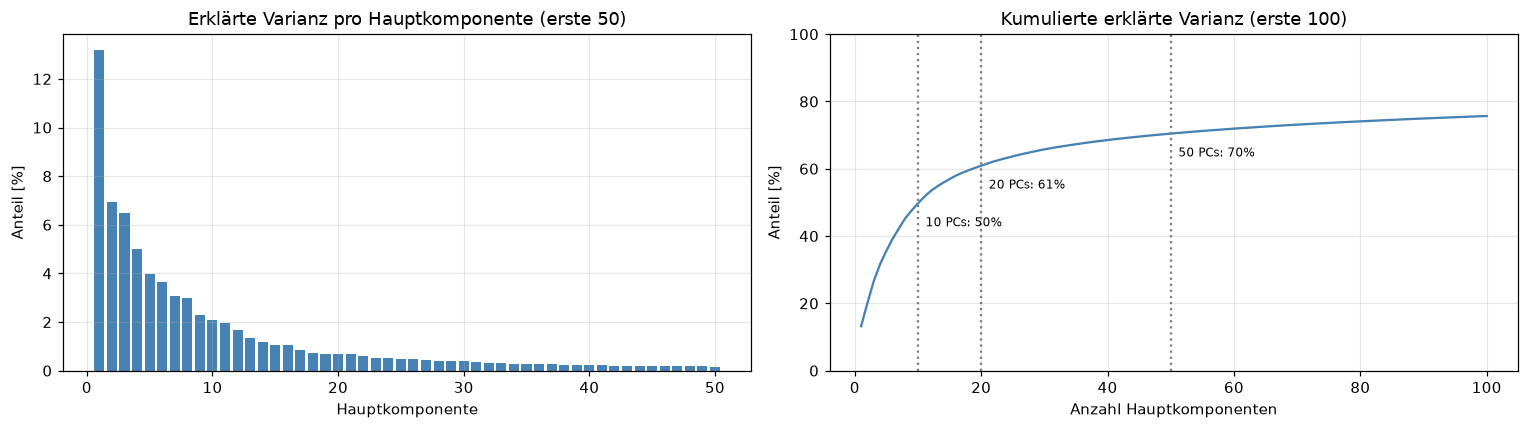

Erste   1 PCs: 13.2% der Varianz
Erste   2 PCs: 20.1% der Varianz
Erste   5 PCs: 35.6% der Varianz
Erste  10 PCs: 49.7% der Varianz
Erste  20 PCs: 60.9% der Varianz
Erste  50 PCs: 70.4% der Varianz
Erste 100 PCs: 75.7% der Varianz


In [6]:
cum = np.cumsum(explained)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].bar(np.arange(1, 51), explained[:50] * 100, color="steelblue")
axes[0].set(title="Erklärte Varianz pro Hauptkomponente (erste 50)", xlabel="Hauptkomponente", ylabel="Anteil [%]")
axes[1].plot(np.arange(1, N_COMP + 1), cum * 100, color="steelblue")
for k in [10, 20, 50]:
    axes[1].axvline(k, color="gray", ls=":")
    axes[1].annotate(f"{k} PCs: {cum[k - 1]:.0%}", (k, cum[k - 1] * 100), xytext=(5, -15), textcoords="offset points", fontsize=8)
axes[1].set(title=f"Kumulierte erklärte Varianz (erste {N_COMP})", xlabel="Anzahl Hauptkomponenten", ylabel="Anteil [%]", ylim=(0, 100))
plt.tight_layout()
plt.show()
for k in [1, 2, 5, 10, 20, 50, 100]:
    print(f"Erste {k:3d} PCs: {cum[k - 1]:.1%} der Varianz")

**Beobachtung:**
- Die erste Hauptkomponente erklärt etwa 13 % der Varianz, die ersten 10 zusammen etwa die Hälfte, die ersten 50 etwa 70 %.
  Statt 16.711 Genen genügen also wenige Dutzend Achsen für den Großteil der Struktur.
- Nach etwa 15–20 Komponenten flacht die Kurve deutlich ab („Knick“). Danach bringt jede weitere Achse nur noch wenig; dort steckt vor allem
  Rauschen und Variation einzelner Proben.
- Es gibt **keine** klare Grenze: Der Rest der Varianz verteilt sich auf sehr viele kleine Komponenten. Die Wahl der Zahl der PCs ist deshalb
  eine Entscheidung (siehe offene Fragen); für Abschnitt 7 nehmen wir pragmatisch 50.

## 5. Die Proben in den ersten Hauptkomponenten

Jeder Punkt ist ein Tumor, die Farbe ist sein **Tumortyp** (33 Farben, Zuordnung in der Legende).

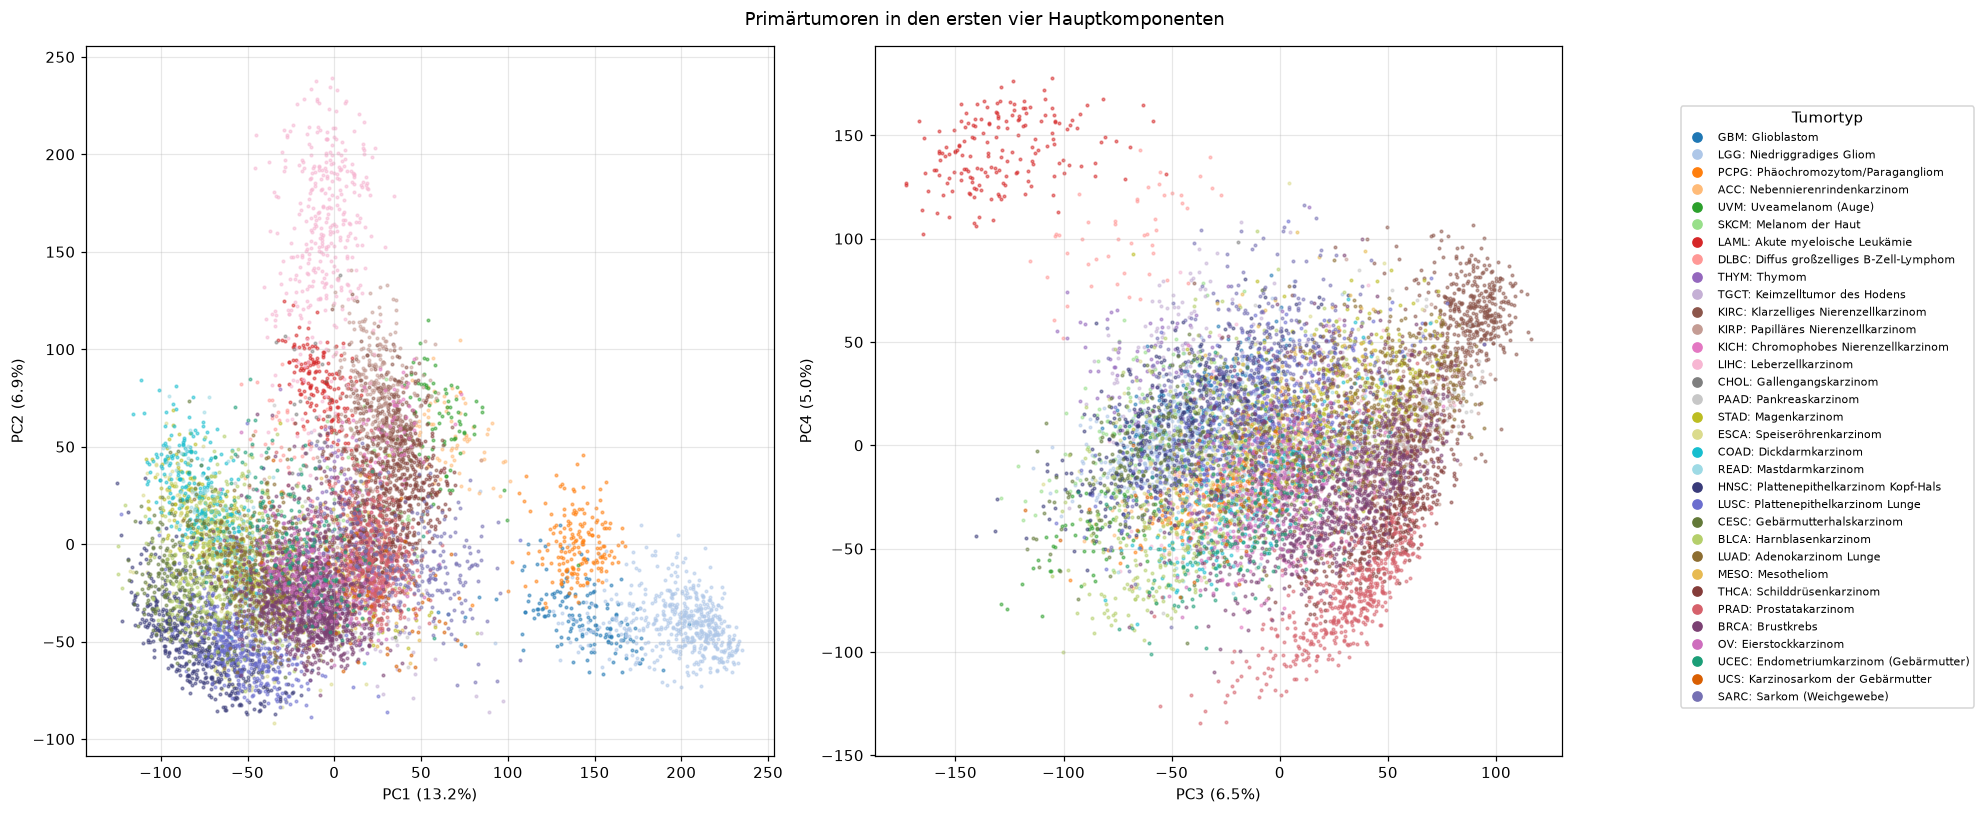

In [7]:
palette = list(plt.cm.tab20.colors) + list(plt.cm.tab20b.colors[::2]) + list(plt.cm.Dark2.colors[:3])   # 33 Farben
color = dict(zip(TYPES, palette))

def pc_plot(ax, i, j):
    for s in TYPES:
        m = (meta["study"] == s).to_numpy()
        ax.scatter(Z[m, i], Z[m, j], s=3, alpha=0.5, color=color[s])
    ax.set(xlabel=f"PC{i + 1} ({explained[i]:.1%})", ylabel=f"PC{j + 1} ({explained[j]:.1%})")

fig, axes = plt.subplots(1, 2, figsize=(18, 7.5))
pc_plot(axes[0], 0, 1)
pc_plot(axes[1], 2, 3)
handles = [plt.Line2D([], [], marker="o", ls="", ms=6, color=color[s], label=f"{s}: {NAME[s]}") for s in TYPES]
fig.legend(handles=handles, loc="center right", fontsize=7.5, title="Tumortyp")
fig.suptitle("Primärtumoren in den ersten vier Hauptkomponenten")
plt.tight_layout(rect=(0, 0, 0.8, 1))
plt.show()

**Beobachtungen:**
- **PC1** trennt die **Hirntumoren** (LGG, GBM) und die Nebennierentumoren (PCPG, weniger ACC) von allen anderen. Auf der Gegenseite liegen die
  Karzinome, also Tumoren aus Epithelgewebe (Darm, Plattenepithel). Die größte Variation im Datensatz ist also „Nervengewebe gegen Epithel“.
- **PC2** hebt die **Leber** (LIHC) und die **Leukämie** (LAML) heraus; am anderen Ende liegen Lunge (LUSC), Kopf-Hals (HNSC) und Pankreas.
- **PC3/PC4**: Die Leukämie (LAML) und das Lymphom (DLBC) liegen weit oben links, die **Niere** (KIRC) rechts, die **Prostata** (PRAD) unten.
- Die meisten Karzinome **überlappen** in den ersten vier Achsen zu einer großen Wolke. Vier Achsen reichen nicht, um 33 Tumortypen zu trennen;
  die Feinstruktur steckt in weiteren Komponenten (Abschnitt 7).
- Schon hier liegen manche Tumortypen auffällig nah beieinander, z. B. ESCA, HNSC, LUSC und CESC (links unten im linken Bild).

## 6. Was bedeuten die Achsen? Die Gene mit den größten Gewichten

Jede Hauptachse $v_j$ (eine Zeile von $V^\top$) ist ein Einheitsvektor im Gen-Raum, also eine gewichtete Kombination aller Gene:
$$v_j = \sum_g v_{jg} \, e_g,$$
wobei $e_g$ die Achse von Gen $g$ ist. Die Gewichte $v_{jg}$ heißen **Ladungen** (*loadings*).
Der **Score** einer Probe auf PC$j$ ist dann
$$z_j = \sum_g v_{jg} \, (x_g - \bar{x}_g).$$

Ein Gen mit großem $|v_{jg}|$ geht also stark in die Achse ein: Proben, in denen dieses Gen hoch (bzw. niedrig) exprimiert ist, bekommen auf dieser
Achse einen großen positiven (bzw. negativen) Score. Die Gene mit den größten positiven und negativen Ladungen zeigen deshalb,
welchen Unterschied die Achse beschreibt. Das **Vorzeichen** einer Achse ist willkürlich ($-v$ ist genauso eine Lösung wie $v$);
nur der Gegensatz zwischen den beiden Enden zählt.

Hinweis: Da wir nicht standardisiert haben, bekommen Gene mit großer Varianz tendenziell größere Ladungen (siehe offene Fragen).

In [8]:
def top_genes(j, k=10):
    order = np.argsort(Vt[j])                                       # Ladungen von PC j, aufsteigend sortiert
    return genes["name"].to_numpy()[order[::-1][:k]], genes["name"].to_numpy()[order[:k]]

rows = []
for j in range(4):
    pos_g, neg_g = top_genes(j)
    rows.append({"PC": f"PC{j + 1}", "Ende": "+", "Gene (größte Ladungen)": ", ".join(pos_g)})
    rows.append({"PC": f"PC{j + 1}", "Ende": "−", "Gene (größte Ladungen)": ", ".join(neg_g)})
pd.set_option("display.max_colwidth", 120)
pd.DataFrame(rows).set_index(["PC", "Ende"])

Gene (größte Ladungen)
PC  Ende                                                                         
PC1 +             GFAP, PLP1, GPM6A, SCG3, ATCAY, BEX1, KIF1A, ATP1A2, AQP4, NCAN
    −          CEACAM6, SFN, TMPRSS4, LCN2, AGR2, TNS4, RAB25, FXYD3, KRT17, GPX2
PC2 +              ALDOB, CDHR5, AMBP, ALB, PKLR, AGXT, SLC39A5, PRAP1, KNG1, HGD
    −      SFRP2, KRT17, CDH3, CLCA2, CNTN1, COL11A1, WNT7B, FXYD3, A2ML1, TRIM29
PC3 +            HPN, SLC34A2, HGD, PIGR, CLDN3, CLDN2, LRP2, C7, TSPAN1, SLC44A4
    −                A2ML1, DPF1, DLL3, GJB6, APC2, FSD1, KIF18B, SOX15, DDN, INA
PC4 +         TFEC, PTPRC, DOCK2, CD84, CR1, GBP5, MS4A1, TLR8, NCKAP1L, KIAA0125
    −     AGR2, SPDEF, CLDN3, RAB25, GRHL2, ESRP1, EPN3, PPP1R1B, C19orf46, AP1M2

**Beobachtungen:** Die Achsen lassen sich gut als **Gewebe- bzw. Zellprogramme** lesen:

| PC | Ende $+$ | Ende $-$ |
|---|---|---|
| PC1 | **Nervengewebe**: `GFAP` (Glia), `PLP1` (Myelin), `AQP4` (Astrozyten) | **Drüsen-/Schleimhautepithel**: `CEACAM6`, `AGR2`, `LCN2` |
| PC2 | **Leberstoffwechsel**: `ALB` (Albumin), `ALDOB`, `KNG1` (Kininogen) | **Plattenepithel/Basalzellen** (`KRT17`, `CDH3`, `TRIM29`) und **Bindegewebe** (Kollagen `COL11A1`, `SFRP2`) |
| PC3 | **Nierenkanälchen und Drüsen**: `LRP2`, `CLDN2`, `SLC34A2` | **Nerven- und Pigmentzellen** (Neuralleiste): `DLL3`, `INA` |
| PC4 | **Immunzellen**: `PTPRC` (CD45), `MS4A1` (B-Zellen), `TLR8` | **Drüsenepithel**: `AGR2`, `SPDEF`, `GRHL2` |

## 7. Welche Tumortypen liegen nah beieinander?

Zwei Bilder zeigen nur zwei Achsen. Wir nutzen deshalb die **ersten 50 Hauptkomponenten** und fragen für jede Probe:
Aus welchen Tumortypen stammen ihre **15 nächsten Nachbarn** (euklidischer Abstand)? Für jedes Paar von Tumortypen A und B ergibt das den Anteil
der Nachbarn von A-Proben, die zu B gehören.

- Ein hoher Anteil **im eigenen Typ** heißt: Der Tumortyp bildet eine eigene Gruppe.
- Ein hoher Anteil **in einem anderen Typ** heißt: Die beiden Typen fließen ineinander (Kandidat für eine Zusammenlegung).

Das ist noch kein Clustering, aber es misst direkt, welche Tumoren sich in der reduzierten Darstellung ähneln.

In [9]:
N_PC, K = 50, 15
Y = Z[:, :N_PC].astype(np.float32)
sq = (Y**2).sum(axis=1)
nbrs = np.empty((n, K), dtype=np.int64)
for start in range(0, n, 2000):                                     # Abstände blockweise, um Speicher zu sparen
    d2 = sq[start:start + 2000, None] - 2 * Y[start:start + 2000] @ Y.T + sq[None, :]
    d2[np.arange(d2.shape[0]), np.arange(start, start + d2.shape[0])] = np.inf   # sich selbst ausschließen
    nbrs[start:start + 2000] = np.argpartition(d2, K, axis=1)[:, :K]

study = meta["study"].to_numpy()
pairs = pd.crosstab(np.repeat(study, K), study[nbrs.ravel()], normalize="index")   # Zeile A: Anteil der Nachbarn aus Typ B
pairs.index.name, pairs.columns.name = "Tumortyp", "Nachbar-Tumortyp"

same_type = np.diag(pairs.loc[pairs.index, pairs.index])
print(f"Anteil der Nachbarn aus demselben Tumortyp: im Mittel {same_type.mean():.0%}")
print(pd.Series(same_type, index=pairs.index).sort_values().head(8).map("{:.0%}".format).rename("Anteil eigener Typ").to_frame().T)

long = pairs.stack().rename("Anteil").reset_index()
long = long[long["Tumortyp"] != long["Nachbar-Tumortyp"]]                # nur Paare verschiedener Typen
cross = long[long["Anteil"] >= 0.05].sort_values("Anteil", ascending=False)
cross.assign(**{"Name": cross["Tumortyp"].map(NAME), "Name Nachbar": cross["Nachbar-Tumortyp"].map(NAME),
                "Anteil": cross["Anteil"].map("{:.0%}".format)}).reset_index(drop=True)

Anteil der Nachbarn aus demselben Tumortyp: im Mittel 85%
Tumortyp           READ ESCA CHOL  UCS COAD UCEC  GBM STAD
Anteil eigener Typ  29%  43%  52%  55%  72%  78%  78%  79%


,Tumortyp,Nachbar-Tumortyp,Anteil,Name,Name Nachbar
0,READ,COAD,68%,Mastdarmkarzinom,Dickdarmkarzinom
1,CHOL,LIHC,30%,Gallengangskarzinom,Leberzellkarzinom
2,ESCA,STAD,27%,Speiseröhrenkarzinom,Magenkarzinom
3,COAD,READ,22%,Dickdarmkarzinom,Mastdarmkarzinom
4,UCS,UCEC,21%,Karzinosarkom der Gebärmutter,Endometriumkarzinom (Gebärmutter)
5,GBM,LGG,20%,Glioblastom,Niedriggradiges Gliom
6,ESCA,HNSC,14%,Speiseröhrenkarzinom,Plattenepithelkarzinom Kopf-Hals
7,STAD,ESCA,12%,Magenkarzinom,Speiseröhrenkarzinom
8,ESCA,LUSC,10%,Speiseröhrenkarzinom,Plattenepithelkarzinom Lunge
9,KICH,KIRC,9%,Chromophobes Nierenzellkarzinom,Klarzelliges Nierenzellkarzinom


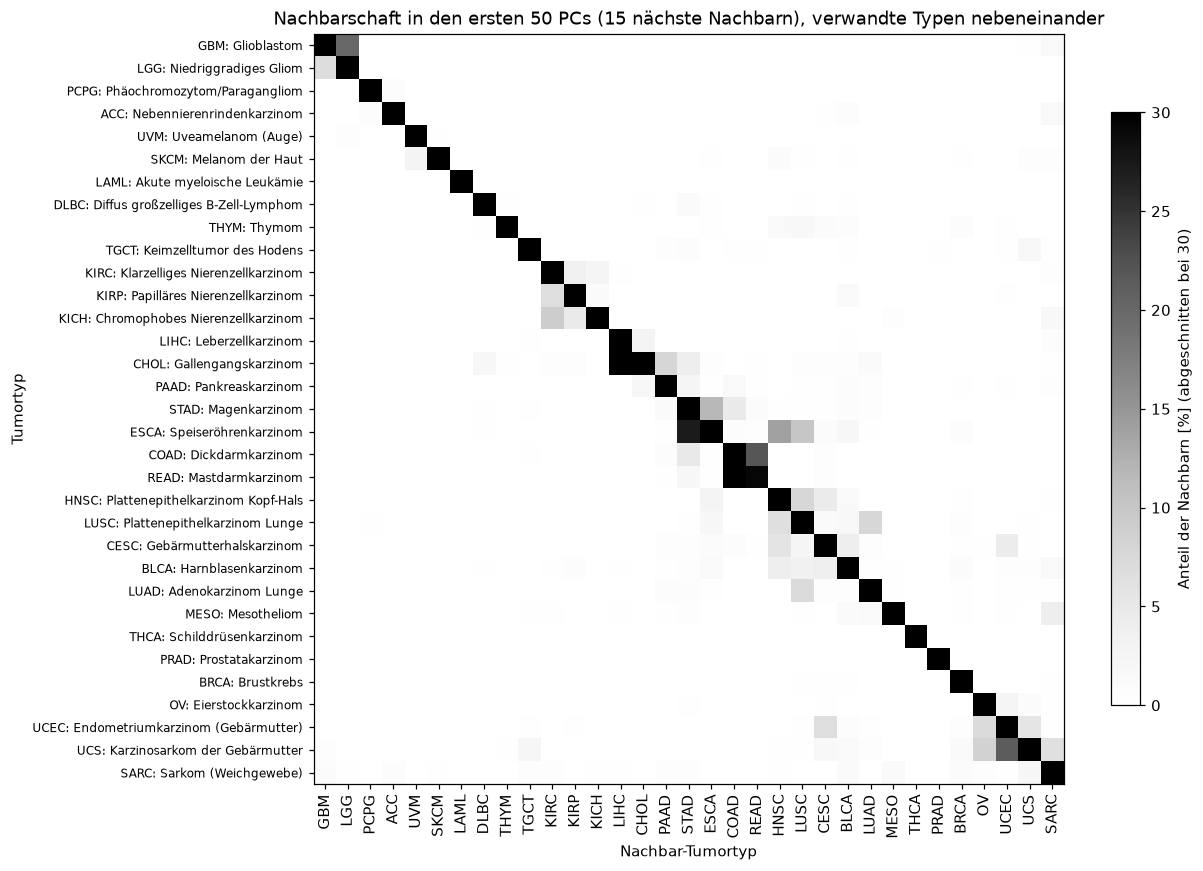

In [10]:
fig, ax = plt.subplots(figsize=(11, 10))
order = TYPES
im = ax.imshow(pairs.loc[order, order] * 100, cmap="Greys", vmax=30)
ax.set_xticks(range(len(order)), order, rotation=90)
ax.set_yticks(range(len(order)), [f"{s}: {NAME[s]}" for s in order], fontsize=8)
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.7, label="Anteil der Nachbarn [%] (abgeschnitten bei 30)")
ax.set(title=f"Nachbarschaft in den ersten {N_PC} PCs ({K} nächste Nachbarn), verwandte Typen nebeneinander",
       xlabel="Nachbar-Tumortyp", ylabel="Tumortyp")
plt.show()

**Beobachtungen:**
- **Die meisten Tumortypen bilden eine eigene Gruppe:** Im Mittel stammen 85 % der Nachbarn aus demselben Tumortyp.
- **Deutlich weniger eigenständig** sind READ (29 %), ESCA (43 %), CHOL (52 %) und UCS (55 %). Das sind die Kandidaten für Abweichungen.
- **Zusammenlegungen**, also Paare mit hohem Nachbaranteil, lassen sich in zwei Arten einteilen:

| Art | Tumortypen | naheliegende Erklärung |
|---|---|---|
| gleiches Organ | READ ↔ COAD (68 % bzw. 22 %) | Mast- und Dickdarm: praktisch derselbe Tumor |
| | GBM ↔ LGG, KICH/KIRP → KIRC, LUAD ↔ LUSC, UCS ↔ UCEC | Subtypen eines Organs, die sich teilweise überlappen |
| verschiedene Organe, gleicher Gewebetyp | ESCA, HNSC, LUSC, CESC | Plattenepithelkarzinome |
| | ESCA ↔ STAD | Adenokarzinome des oberen Verdauungstrakts |
| verschiedene Organe, gemeinsame Herkunft | CHOL → LIHC, PAAD | Leber, Gallengang und Pankreas entstehen aus derselben Anlage; Gallengangstumoren liegen oft in der Leber |
| | UCS, UCEC → OV, UCEC → CESC, UCS → SARC | gynäkologische Tumoren (Müller-Gang); Karzinosarkome enthalten Bindegewebe |

- **ESCA** ist der deutlichste Kandidat für eine **Aufspaltung**: Seine Nachbarn stammen zu großen Teilen aus Magen (STAD) **und** aus
  Plattenepithelkarzinomen (HNSC, LUSC). Das passt dazu, dass Speiseröhrenkrebs zwei Gewebetypen umfasst (Adeno- und Plattenepithelkarzinom).
- Die Anteile sind **nicht symmetrisch**: Kleine Tumortypen (READ, CHOL, UCS, ESCA) haben viele Nachbarn in großen Typen, umgekehrt kaum.
  Das liegt zum Teil einfach an den Gruppengrößen.

## 8. Zusammenfassung und offene Fragen

**Erstes Ergebnis zur Forschungsfrage:** Schon eine einfache PCA zeigt, dass die meisten Tumortypen in der Genexpression **eigene Gruppen** bilden.
Die Abweichungen folgen dem **Gewebe**: Zusammen liegen Tumortypen desselben Organs (COAD/READ), desselben Gewebetyps aus verschiedenen Organen
(Plattenepithel, Adenokarzinome des Verdauungstrakts) und mit gemeinsamer Entwicklungsherkunft (Leber–Galle–Pankreas, gynäkologische Tumoren).
ESCA ist ein Kandidat für eine Aufspaltung in zwei Gruppen. Die Hauptachsen selbst sind als Gewebe- und Zellprogramme interpretierbar
(Nervengewebe, Epithel, Leber, Immunzellen).

Das sind erste Hinweise, noch keine belastbaren Ergebnisse. Für die weitere Arbeit sind folgende Fragen offen:

**Daten und Vorverarbeitung**
1. **Batch-Effekte:** Die Proben vom älteren GA-Gerät haben wir weggelassen. Es bleiben Unterschiede zwischen Sequenzierzentren
   (GBM, LAML, OV, STAD, ESCA wurden teils woanders gemessen) und zwischen Platten. Wie viel der Trennung ist Technik?
   Prüfen: PCs nach Zentrum und Platte einfärben, am besten innerhalb eines Tumortyps.
2. **Fehlende Werte:** Wir haben alle 3.820 Gene mit NaN entfernt, darunter Marker wie `KRT5` oder die Y-chromosomalen Gene. Ist das die beste Lösung?
3. **Geschlecht:** Geschlechtsgene wie `XIST` streuen stark, und einige Tumortypen betreffen nur ein Geschlecht. Bilden sie eine eigene Achse? Entfernen?
4. **Qualität:** Proben mit auffällig vielen Nullen, Qualitätswarnungen oder widersprüchlichem Geschlecht haben wir nicht betrachtet.

**Methode**

5. **Standardisieren:** Wir haben nur zentriert. Mit Standardisierung pro Gen zählt jedes Gen gleich. Ändert das die Achsen?
6. **Genauswahl:** Alle 16.711 Gene oder nur die Top-k nach Varianz (welches k)?
7. **Zahl der Hauptkomponenten:** 50 ist eine pragmatische Wahl. Ändern sich die Nachbarschaften bei 20 oder 100?
8. **Ungleiche Gruppengrößen:** BRCA hat 30-mal so viele Proben wie CHOL. Große Typen prägen die Achsen und „ziehen“ Nachbarn an. Gleich viele Proben pro Typ ziehen?
9. **Nachbarschaft als Maß:** Die Wahl k = 15 und der euklidische Abstand sind Setzungen. Wie robust sind die Paare?
10. **Aufspaltungen erkennen:** Die Nachbarschaft zeigt gut, welche Typen ineinanderfließen, aber kaum, ob ein Typ in mehrere Gruppen zerfällt.
    Das kann erst ein Clustering zeigen (ein Typ verteilt sich auf mehrere Cluster).

**Nächste Schritte im Projekt**

11. **Nichtlineare Methode (z. B. UMAP):** Trennt sie die große Karzinom-Wolke besser als PCA?
12. **Clustering:** Stimmen die Cluster mit den Tumortypen überein (gemessen mit dem ARI), und bilden die hier gefundenen Paare gemeinsame Cluster? (spektrales Clustering und ein zweites Verfahren)
13. **Gewebetyp prüfen:** Liegen bei ESCA (und CESC) die Adeno- und Plattenepithelkarzinome tatsächlich bei ihren jeweiligen Gegenstücken?
    Die Angabe steht in der CDR-Tabelle (`histological_type`).